In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip install plotly

In [7]:
cb=pd.read_csv('cust_bio.csv')
sp=pd.read_csv('sp.csv')
ca=pd.read_csv('cust_activity.csv')
orders=pd.read_csv('orders (1).csv')
cs=pd.read_csv('cust_sub.csv')

In [9]:
print(cb.shape)
print(sp.shape)
print(ca.shape)
print(orders.shape)
print(cs.shape)

(478, 3)
(6, 5)
(7500, 3)
(127, 4)
(51, 3)


In [8]:
print(cb.columns)
print(sp.columns)
print(ca.columns)
print(orders.columns)
print(cs.columns)

Index(['Cust_ID', 'City', 'Age'], dtype='str')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')
Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')


In [ ]:
#  Check null values and duplicates in each df. Create Functions for the same

In [16]:
def check_null_dup(data):
    dup=data.duplicated().sum()
    nv=data.isnull().sum()
    if dup == 0 and nv.sum()==0: 
        print('No Duplicates and No null values')

    else:
      return dup,nv

In [17]:
check_null_dup(cb)
check_null_dup(ca)
check_null_dup(cs)
check_null_dup(sp)
check_null_dup(orders)

No Duplicates and No null values
No Duplicates and No null values
No Duplicates and No null values
No Duplicates and No null values
No Duplicates and No null values


In [20]:
import plotly.express as px

In [19]:
# Find Count of Customers from each city and represent it on bar chart.
q2= cb['City'].value_counts().reset_index()
q2

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


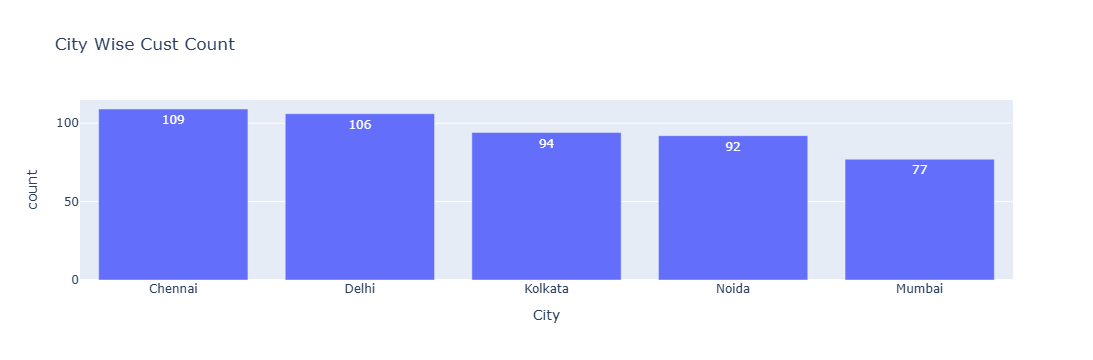

In [21]:
fig = px.bar(data_frame=q2,x='City',y='count',text='count',
             title='City Wise Cust Count')
fig.show()

In [22]:
# Find Range Age wise count of cutsomers, represent it on pie chart.
cb['Age'].describe()

count    478.000000
mean      28.740586
std        5.376756
min       20.000000
25%       24.000000
50%       29.000000
75%       34.000000
max       37.000000
Name: Age, dtype: float64

In [23]:
cb['Age_Range'] = pd.cut(cb['Age'],bins=[19,23,27,31,35,39])
cb['Age_Range'] = cb['Age_Range'].astype(str)

In [24]:
q3=cb['Age_Range'].value_counts().reset_index()
q3

,Age_Range,count
0,"(31, 35]",116
1,"(19, 23]",112
2,"(23, 27]",95
3,"(27, 31]",93
4,"(35, 39]",62


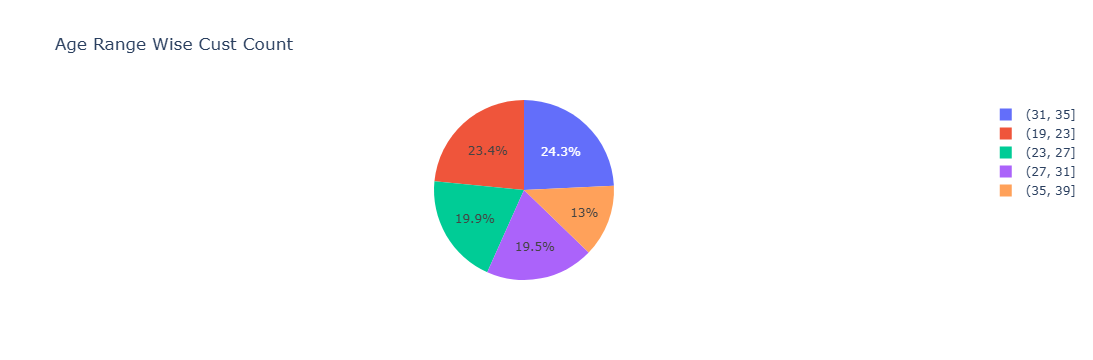

In [26]:
fig = px.pie(data_frame=q3,names='Age_Range',values='count',
             title='Age Range Wise Cust Count')
fig.show()

In [31]:
# Find Count of each activity, represent it on bar chart?
q4= ca['Activity'].value_counts().reset_index()
q4

,Activity,count
0,Browse,6548
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


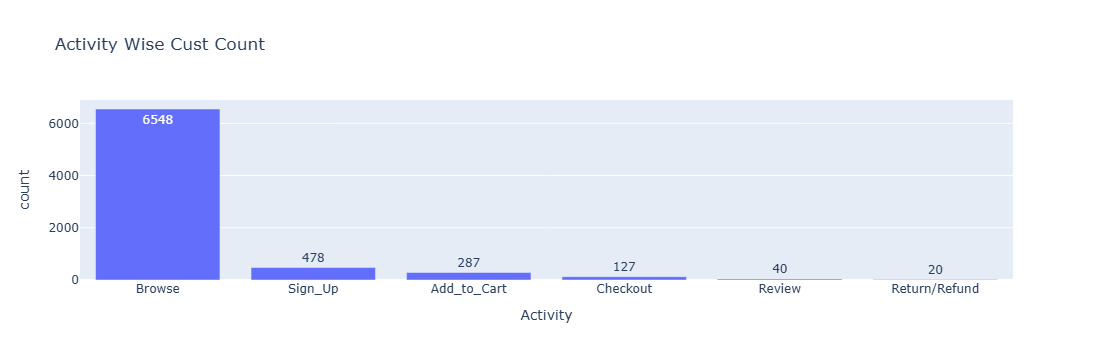

In [30]:
fig = px.bar(data_frame=q4,x='Activity',y='count',text='count',
             title='Activity Wise Cust Count')
fig.show()

In [36]:
ca['Date']=pd.to_datetime(ca['Date'])

In [37]:
# Find order month wise total amount. Represent it on line chart.
ca_cout = ca[ca['Activity']=='Checkout']
ca_cout.shape

(127, 3)

In [38]:
q5=pd.merge(orders,ca_cout,on='Cust_ID')
q5['Order_Month'] = q5['Date'].dt.month
q5.head()

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,Order_Month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7
3,ORD_74,CUS_360,5736.31,COD,Checkout,2025-05-24,5
4,ORD_75,CUS_714,1592.53,Debit Card,Checkout,2024-06-19,6


In [39]:
q5_ans = q5.groupby('Order_Month')['Amount'].sum().reset_index()
q5_ans

,Order_Month,Amount
0,1,27022.20
1,2,70477.42
2,3,74777.59
3,4,88080.66
4,5,60200.46
5,6,69580.07
6,7,80416.05
7,8,27227.29
8,9,34804.62
9,10,30298.38


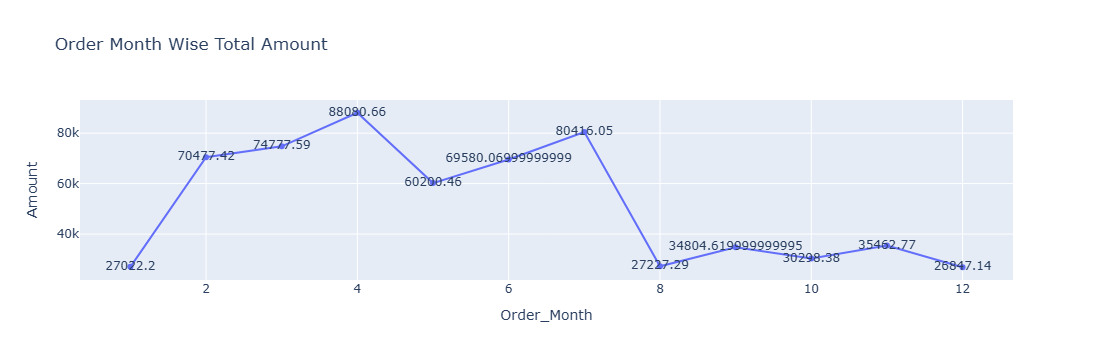

In [44]:
fig = px.line(data_frame=q5_ans,x='Order_Month',y='Amount', text='Amount',
             title='Order Month Wise Total Amount')
fig.show()

In [45]:
# Find Sub_Plan wise total revenue generated. Represent it on bar chart.
cs_sp = pd.merge(cs,sp,on='Plan_Var_ID')
cs_sp.head()

,Cust_ID,Plan_Var_ID,Purchase_Date,Plan_ID,Plan_name,Price,Duration
0,CUS_626,P1_1Y,2025-05-15,P1,Silver,1200.0,1 Year
1,CUS_723,P1_1Y,2024-07-23,P1,Silver,1200.0,1 Year
2,CUS_575,P1_1Y,2024-11-14,P1,Silver,1200.0,1 Year
3,CUS_232,P2_6M,2025-04-19,P2,Gold,1440.0,6 Months
4,CUS_346,P2_1Y,2024-01-31,P2,Gold,2400.0,1 Year


In [46]:
q6= cs_sp.groupby('Plan_Var_ID')['Price'].sum().reset_index()
q6

,Plan_Var_ID,Price
0,P1_1Y,16800.0
1,P1_6M,5040.0
2,P2_1Y,24000.0
3,P2_6M,7200.0
4,P3_1Y,28800.0
5,P3_6M,25920.0


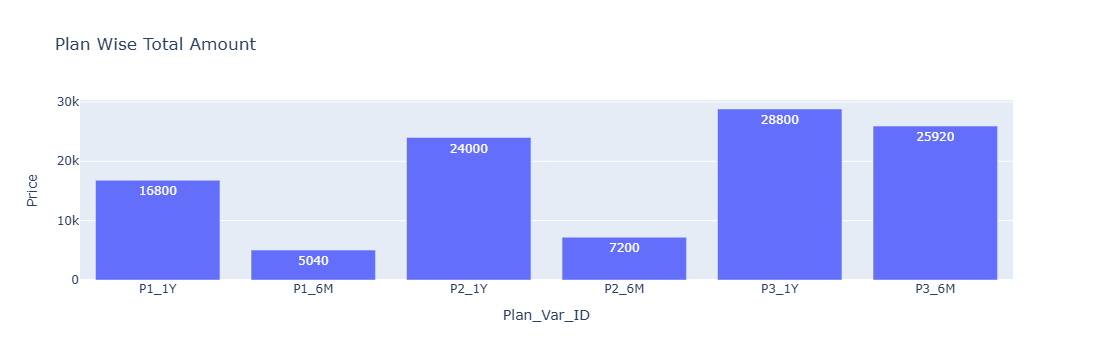

In [48]:
fig = px.bar(data_frame=q6,x='Plan_Var_ID',y='Price', text='Price',
             title='Plan Wise Total Amount')
fig.show()

In [53]:
# City wise find total amount?
cb_od = pd.merge(cb,orders,on='Cust_ID')
cb_od.head()

,Cust_ID,City,Age,Age_Range,Order_id,Amount,Payment_mode
0,CUS_121,Noida,30,"(27, 31]",ORD_83,3336.69,UPI
1,CUS_127,Delhi,24,"(23, 27]",ORD_172,6427.90,Credit_Card
2,CUS_129,Mumbai,20,"(19, 23]",ORD_97,8653.62,UPI
3,CUS_135,Kolkata,35,"(31, 35]",ORD_87,2551.37,Credit_Card
4,CUS_139,Noida,34,"(31, 35]",ORD_127,3290.14,UPI


In [55]:
q7= cb_od.groupby('City')['Amount'].sum().reset_index()
q7

,City,Amount
0,Chennai,96763.72
1,Delhi,147176.17
2,Kolkata,102185.83
3,Mumbai,120515.98
4,Noida,158552.95


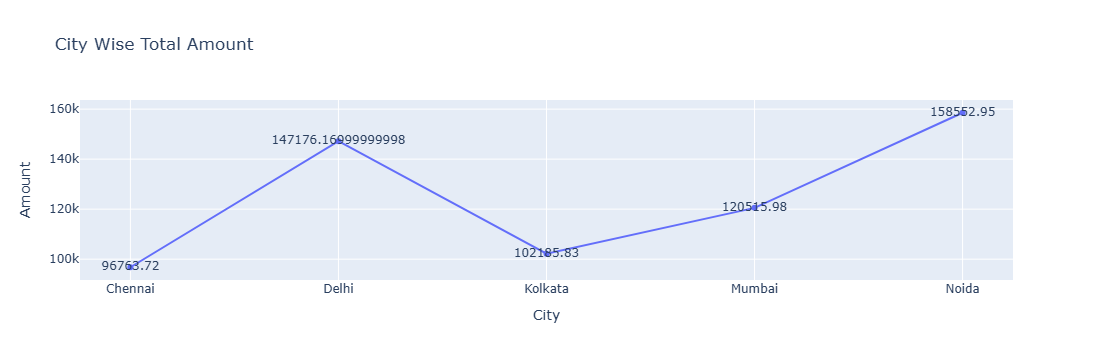

In [56]:
fig = px.line(data_frame=q7,x='City',y='Amount', text='Amount',
             title='City Wise Total Amount')
fig.show()

In [49]:
# Find count of each payment mode, represent it on donut chart?
q8=orders['Payment_mode'].value_counts().reset_index()
q8

,Payment_mode,count
0,Net Banking,29
1,Debit Card,27
2,UPI,24
3,Credit_Card,24
4,COD,23


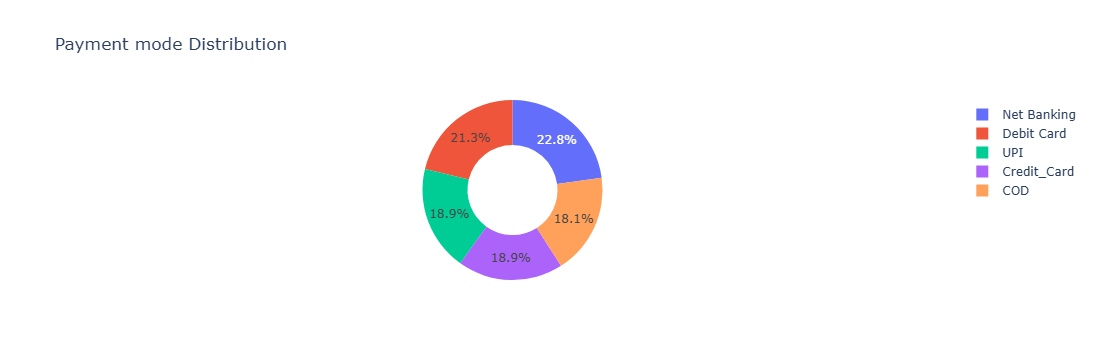

In [50]:
fig = px.pie(data_frame=q8,names='Payment_mode',values='count',hole=0.5,
             title='Payment mode Distribution')
fig.show()

In [86]:
# Represent Payment mode wise sum of amount on a strip plot?
q9=orders.groupby('Payment_mode')['Amount'].sum().reset_index()
q9

,Payment_mode,Amount
0,COD,115972.27
1,Credit_Card,127611.89
2,Debit Card,133145.11
3,Net Banking,137780.34
4,UPI,110685.04


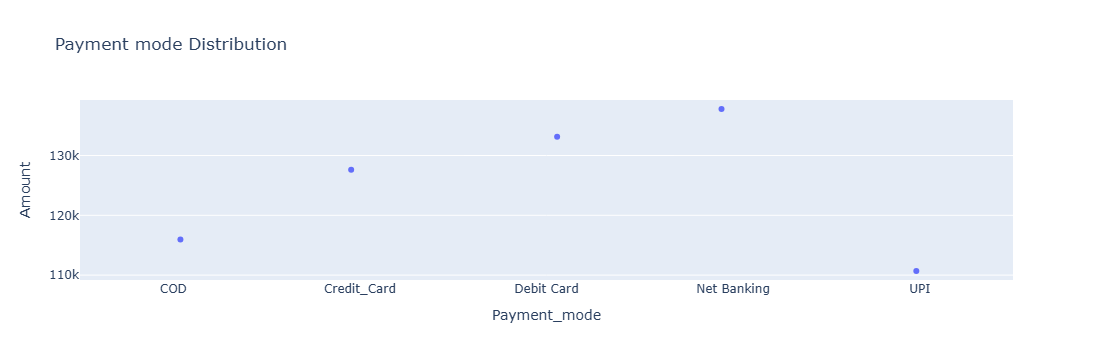

In [89]:
fig = px.strip(data_frame=q9,x='Payment_mode',y='Amount',
             title='Payment mode Distribution')
fig.show()

#### FUNNEL ANALYSIS

In [ ]:
# Generate the Entire Funnel. Represent 4 columns
# - Funnel_Stage, Count_of_Cust, Percenatge_Conversion

In [59]:
f1=ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name='count')
f1

,Cust_ID,Activity,count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10
...,...,...,...
1628,CUS_798,Browse,10
1629,CUS_798,Sign_Up,1
1630,CUS_799,Browse,10
1631,CUS_800,Browse,12


In [60]:
funnel=f1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [63]:
funnel['Prev_Count']=np.where(funnel['Activity']=='Return/Refund',
                              funnel['count'].shift(2),funnel['count'].shift(1))
funnel=funnel.fillna(0)
funnel

,Activity,count,Prev_Count
0,Browse,681,0.0
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [66]:
funnel['Conversion%']=round((funnel['count']/funnel['Prev_Count'])*100,2)
funnel=funnel.fillna(0)
funnel

,Activity,count,Prev_Count,Conversion%
0,Browse,681,0.0,inf
1,Sign_Up,478,681.0,70.19
2,Add_to_Cart,287,478.0,60.04
3,Checkout,127,287.0,44.25
4,Review,40,127.0,31.50
5,Return/Refund,20,127.0,15.75


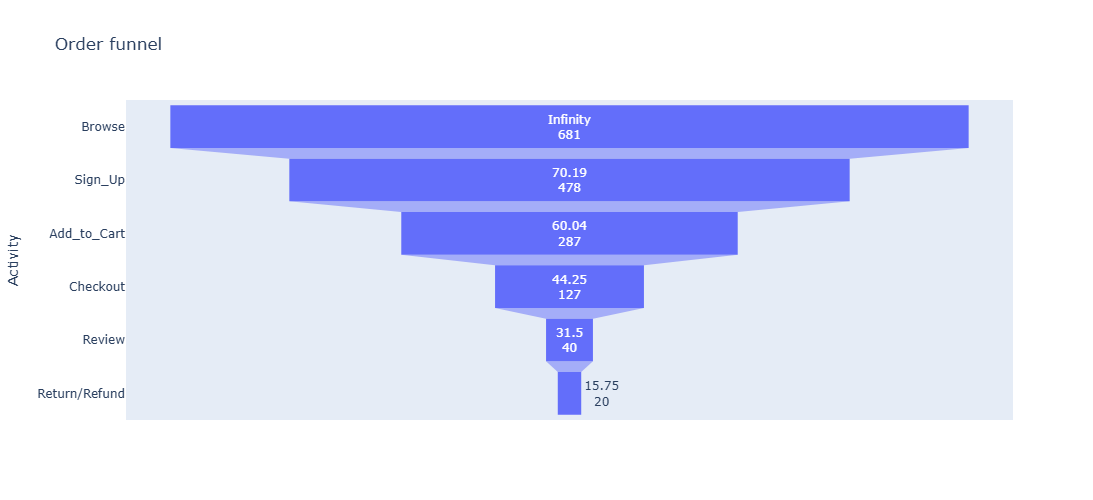

In [67]:
Find Avg_Days to transition from one Funnel stage to the next stage.

In [69]:
# Find Customer wise count of days to transition from one stage of funnel to the next stage?
pt1=pd.pivot_table(data=ca,index='Cust_ID',columns='Activity',values='Date',aggfunc='min')
pt1.head(10)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21


In [70]:
pt1['DD_Browse_2Signup']=abs((pt1['Browse']-pt1['Sign_Up']).dt.days)
pt1['DD_Add2Cart_2Browse']=(pt1['Add_to_Cart']-pt1['Browse']).dt.days
pt1['DD_Checkout_2Add2Cart']=(pt1['Checkout']-pt1['Add_to_Cart']).dt.days
pt1['DD_Review_2Checkout']=(pt1['Review']-pt1['Checkout']).dt.days
pt1['DD_Return/Refund_2Checkout']=(pt1['Return/Refund']-pt1['Checkout']).dt.days
pt1.head(10)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,DD_Browse_2Signup,DD_Add2Cart_2Browse,DD_Checkout_2Add2Cart,DD_Review_2Checkout,DD_Return/Refund_2Checkout
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,0.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,1.0,0.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,2.0,NaN,NaN,NaN,NaN
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27,1.0,NaN,NaN,NaN,NaN
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26,2.0,0.0,19.0,NaN,NaN
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21,1.0,0.0,11.0,NaN,NaN


In [71]:
pt2=pt1.iloc[:,-5:]
pt2.head()

Activity,DD_Browse_2Signup,DD_Add2Cart_2Browse,DD_Checkout_2Add2Cart,DD_Review_2Checkout,DD_Return/Refund_2Checkout
Cust_ID,,,,,
CUS_121,3.0,0.0,8.0,NaN,NaN
CUS_122,NaN,NaN,NaN,NaN,NaN
CUS_123,NaN,NaN,NaN,NaN,NaN
CUS_124,1.0,0.0,NaN,NaN,NaN
CUS_125,2.0,NaN,NaN,NaN,NaN


In [77]:
#Find Avg_Days to transition from one Funnel stage to the next stage.
avg_dd=np.round(pt2.mean().values,2)
avg_dd

array([ 2.52,  0.86, 14.43,  2.62,  3.4 ])

In [78]:
# Addind 0 as There is 0 DayDiff from Browse 2 Browse
avg_dd=[0]+list(avg_dd)
avg_dd

[0,
 np.float64(2.52),
 np.float64(0.86),
 np.float64(14.43),
 np.float64(2.62),
 np.float64(3.4)]

In [79]:
funnel['Avg_DayDiff']=avg_dd
funnel

,Activity,count,Prev_Count,Conversion%,Avg_DayDiff
0,Browse,681,0.0,inf,0.00
1,Sign_Up,478,681.0,70.19,2.52
2,Add_to_Cart,287,478.0,60.04,0.86
3,Checkout,127,287.0,44.25,14.43
4,Review,40,127.0,31.50,2.62
5,Return/Refund,20,127.0,15.75,3.40


In [81]:
funnel['Conversion%']=funnel['Conversion%'].apply(lambda x : str(x) + '%')
funnel

,Activity,count,Prev_Count,Conversion%,Avg_DayDiff
0,Browse,681,0.0,inf%,0.00
1,Sign_Up,478,681.0,70.19%,2.52
2,Add_to_Cart,287,478.0,60.04%,0.86
3,Checkout,127,287.0,44.25%,14.43
4,Review,40,127.0,31.5%,2.62
5,Return/Refund,20,127.0,15.75%,3.40


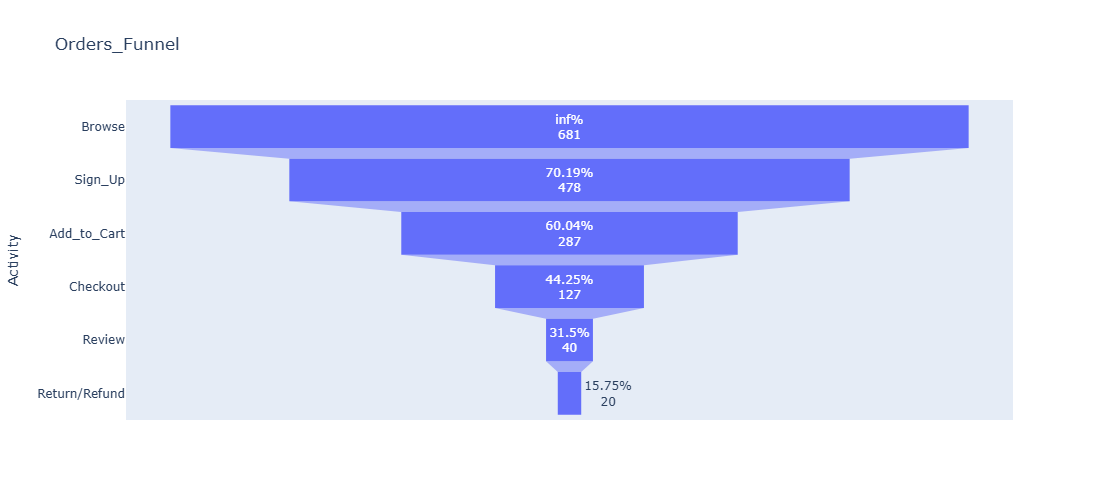

In [82]:
fig=px.funnel(data_frame=funnel,x='count',y='Activity',text='Conversion%',
              hover_data='Avg_DayDiff',title='Orders_Funnel',height=500)
fig.show()